# 5.4 Случайное блуждание и диффузия

# 5.4 随机游走与扩散

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4), "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#356AE6", "#D55E00", "#009E73"]),
    "figure.dpi": 110,
})
from scipy.stats import binom, norm
from itertools import product

## Ансамбль независимых траекторий
Каждый шаг равен $+\ell$ или $-\ell$ с вероятностью 1/2. Все частицы начинают в нуле. Используем $M=20\,000$ траекторий и $N=500$ шагов. Длина и время заданы в условных единицах.

## 独立轨迹的集合
每一步以 1/2 的概率取 $+\ell$ 或 $-\ell$。所有粒子从原点出发。使用 $M=20\,000$ 条轨迹，每条 $N=500$ 步。长度和时间均采用任意单位。

In [2]:
rng = np.random.default_rng(42)
M, N = 20_000, 500
ell, dt = 1.0, 1.0
steps = rng.choice([-ell, ell], size=(M, N))
x = np.cumsum(steps, axis=1)
t = np.arange(1, N + 1) * dt
mean_x = x.mean(axis=0)
msd = np.mean(x**2, axis=0)
D = ell**2 / (2 * dt)
print("x.shape:", x.shape)
print(f"D = {D:.3f}")

x.shape: (20000, 500)
D = 0.500


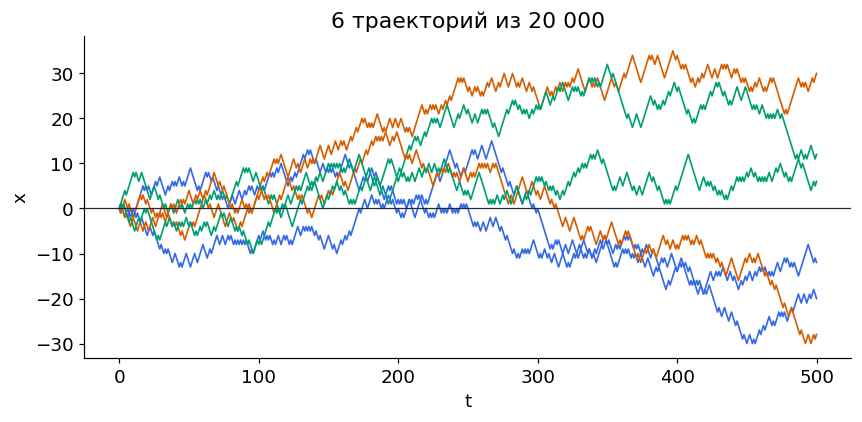

In [3]:
fig, ax = plt.subplots()
for row in x[:6]:
    ax.plot(np.r_[0, t], np.r_[0, row], linewidth=1.1)
ax.axhline(0, color="#202938", linewidth=0.8)
ax.set(xlabel="t", ylabel="x", title="6 траекторий из 20 000")
fig.tight_layout()
plt.show()

## Первые три шага
Переберём все $2^n$ равновероятных последовательностей. В одной точке могут закончиться несколько траекторий.

## 前三步
枚举所有 $2^n$ 条等概率路径。多条路径可能到达同一个终点。

In [4]:
small_step_results = []
for n_steps in (1, 2, 3):
    paths = np.array(list(product([-ell, ell], repeat=n_steps)))
    endpoints = paths.sum(axis=1)
    positions, counts = np.unique(endpoints, return_counts=True)
    probabilities = counts / endpoints.size
    exact_msd = np.mean(endpoints**2)
    small_step_results.append((positions, probabilities, exact_msd))
    print(f"n={n_steps}, x={positions}, P={probabilities}, MSD={exact_msd}")

n=1, x=[-1.  1.], P=[0.5 0.5], MSD=1.0
n=2, x=[-2.  0.  2.], P=[0.25 0.5  0.25], MSD=2.0
n=3, x=[-3. -1.  1.  3.], P=[0.125 0.375 0.375 0.125], MSD=3.0


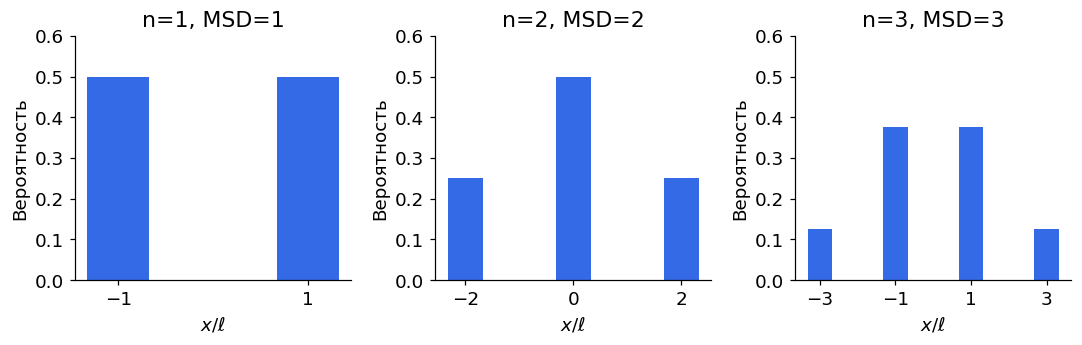

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3))
for n_steps, (ax, result) in enumerate(zip(axes, small_step_results), start=1):
    positions, probabilities, exact_msd = result
    ax.bar(positions / ell, probabilities, width=0.65)
    ax.set(xlabel=r"$x/\ell$", ylabel="Вероятность", ylim=(0, 0.6),
           xticks=positions / ell, title=f"n={n_steps}, MSD={exact_msd:g}")
fig.tight_layout()
plt.show()

## Среднее и MSD
Для симметричных независимых шагов $\mathbb E[x_n]=0$, $\mathbb E[x_n^2]=n\ell^2=2Dt$. Среднее конечного ансамбля отклоняется от нуля. MSD усредняем по частицам (`axis=0`), а не по времени.

## 均值与均方位移
对称独立步长满足 $\mathbb E[x_n]=0$、$\mathbb E[x_n^2]=n\ell^2=2Dt$。有限轨迹集合的均值会偏离零。MSD 沿粒子方向求平均（`axis=0`），不是沿时间求平均。

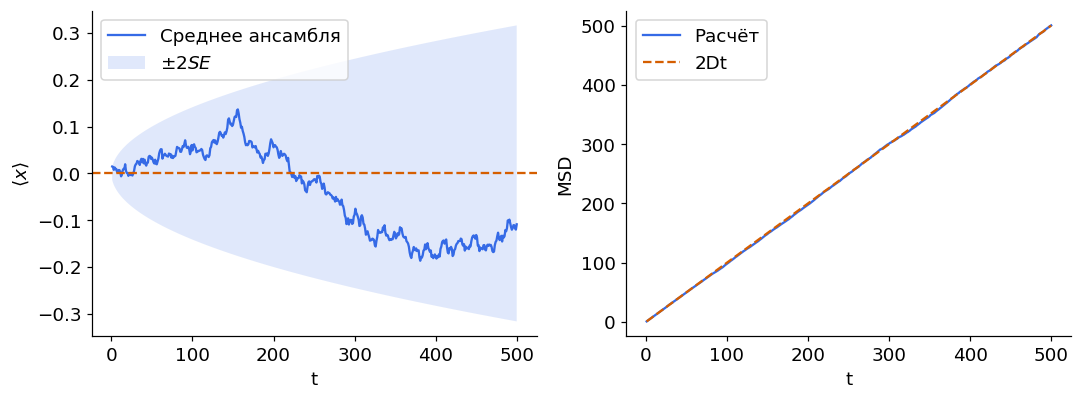

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
mean_se = np.sqrt(2 * D * t / M)
axes[0].plot(t, mean_x, label="Среднее ансамбля")
axes[0].fill_between(t, -2 * mean_se, 2 * mean_se, alpha=0.15,
                     label=r"$\pm 2SE$")
axes[0].axhline(0, color="#D55E00", linestyle="--")
axes[0].set(xlabel="t", ylabel=r"$\langle x \rangle$")
axes[1].plot(t, msd, label="Расчёт")
axes[1].plot(t, 2 * D * t, "--", color="#D55E00", label="2Dt")
axes[1].set(xlabel="t", ylabel="MSD")
for ax in axes:
    ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## Оценка коэффициента диффузии
Используем конечные положения независимых частиц: $D_{MC}=\langle x_N^2\rangle/(2t_N)$. SE вычисляем по разбросу $x_N^2$. Точки MSD в соседние моменты времени коррелируют.

## 扩散系数估计
使用独立粒子的最终位置：$D_{MC}=\langle x_N^2\rangle/(2t_N)$。SE 由 $x_N^2$ 的离散程度计算；相邻时刻的 MSD 数据存在相关性。

In [7]:
final_x = x[:, -1]
D_mc = np.mean(final_x**2) / (2 * t[-1])
SE_D = np.std(final_x**2, ddof=1) / (2 * t[-1] * np.sqrt(M))
print(f"mean(x_N) = {final_x.mean():.5f}")
print(f"MSD = {msd[-1]:.5f}, theory = {N * ell**2:.5f}")
print(f"D_MC = {D_mc:.6f}, SE = {SE_D:.6f}, theory = {D:.6f}")

mean(x_N) = -0.10880
MSD = 500.32240, theory = 500.00000
D_MC = 0.500322, SE = 0.005029, theory = 0.500000


## Распределение конечных положений
После чётного числа шагов доступны только чётные значения $x/\ell$. Поэтому ширина столбца гистограммы равна $2\ell$. Сравниваем плотность гистограммы, точные биномиальные вероятности, делённые на $2\ell$, и нормальное приближение.

## 最终位置分布
偶数步后，$x/\ell$ 只能取偶数。因此直方图的组距取 $2\ell$。比较直方图密度、除以 $2\ell$ 的精确二项概率，以及正态近似。

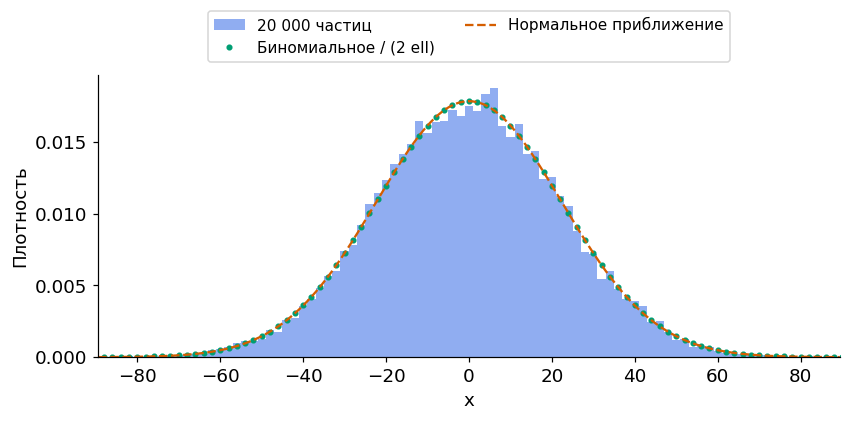

In [8]:
positions = np.arange(-N, N + 1, 2) * ell
bins = np.r_[positions - ell, positions[-1] + ell]
probabilities = binom.pmf(np.arange(N + 1), N, 0.5)
sigma = np.sqrt(N) * ell
grid = np.linspace(-4 * sigma, 4 * sigma, 400)
fig, ax = plt.subplots()
ax.hist(final_x, bins=bins, density=True, alpha=0.55, label="20 000 частиц")
ax.plot(positions, probabilities / (2 * ell), ".", color="#009E73",
        label="Биномиальное / (2 ell)")
ax.plot(grid, norm.pdf(grid, scale=sigma), "--", color="#D55E00",
        label="Нормальное приближение")
ax.set(xlim=(-4 * sigma, 4 * sigma), xlabel="x", ylabel="Плотность")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, fontsize=10)
fig.tight_layout()
plt.show()

## Попробуйте
Удвойте длину шага при прежнем $\Delta t$. Во сколько раз изменятся MSD и $D$? Затем уменьшите число траекторий и сравните шум среднего.

## 练习
保持 $\Delta t$ 不变，将步长加倍。MSD 和 $D$ 分别变为原来的多少倍？再减少轨迹数，比较均值的波动。